# 02 · Exploratory data analysis

**Questions this notebook answers**

1. Is there any feature so predictive that it looks like leakage?
2. Which features separate fraud from legitimate transactions, and how strongly (with uncertainty)?
3. How is money at risk distributed across fraud cases?
4. Do warning signals add up, i.e. is fraud likelier when several red flags co-occur?
5. What does this mean for modelling in the next phase?

**Scope:** only the **dev** split (80%). The holdout stays unseen until the end of modelling
(`notes/00_preregistration.md`). Intervals: 95% Wilson for rates, 95% stratified bootstrap
(1,000 resamples) for AUC.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e import stats as S
from fraud_e2e.data import load_raw
from fraud_e2e.reporting import write_csv, write_json
from fraud_e2e.splits import dev_only

P.set_style()
pd.set_option("display.width", 140)

dev = dev_only(load_raw())
base_rate = dev[C.TARGET].mean()
n_fraud = int(dev[C.TARGET].sum())
print(f"dev: {len(dev):,} rows, {n_fraud} fraud ({100 * base_rate:.3f}%)")

dev: 16,000 rows, 271 fraud (1.694%)


## 1. Leakage screen

Pre-registered alarm: any single feature with univariate ROC-AUC above 0.95 stops work.
Univariate AUC is the probability that a random fraud has a higher value than a random legit
transaction; 0.5 means no signal, values below 0.5 mean *lower* values go with fraud.
`transaction_id` is included only as a check that row order carries no label information.

In [2]:
uni = S.univariate_numeric(dev, C.NUMERIC_COLS + [C.ID_COL], n_boot=1000)
max_sep = uni[uni["feature"] != C.ID_COL].iloc[0]
max_auc_any = float(np.maximum(uni["auc"], 1 - uni["auc"]).max())
id_row = uni.set_index("feature").loc[C.ID_COL]
display(
    Markdown(
        f"Highest direction-free univariate AUC: **{max_auc_any:.3f}** (`{max_sep['feature']}`), "
        f"below the 0.95 alarm. `transaction_id` AUC = {id_row['auc']:.3f} "
        f"(95% CI {id_row['auc_ci_low']:.3f}–{id_row['auc_ci_high']:.3f}), i.e. row order is "
        f"{'not ' if id_row['auc_ci_low'] < 0.5 < id_row['auc_ci_high'] else ''}related to fraud."
    )
)

Highest direction-free univariate AUC: **0.708** (`merchant_risk_score`), below the 0.95 alarm. `transaction_id` AUC = 0.488 (95% CI 0.457–0.519), i.e. row order is not related to fraud.

**A column that needs a decision: `is_ai_generated_scam_attempt`.** Its name could suggest a label
assigned *after* investigating a case, which would leak the outcome. If it were such a label, almost
every flagged row would be fraud. The table checks that.

In [3]:
ai_tab = S.rate_table(dev, "is_ai_generated_scam_attempt")
ai_tab

,feature,level,n,n_fraud,fraud_rate,ci_low,ci_high,lift
0,is_ai_generated_scam_attempt,True,298,24,0.080537,0.054716,0.117035,4.754947
1,is_ai_generated_scam_attempt,False,15702,247,0.015730,0.013899,0.017799,0.928737


In [4]:
ai_true = ai_tab.set_index("level").loc["True"]
display(
    Markdown(
        f"Only **{100 * ai_true['fraud_rate']:.1f}%** (95% CI {100 * ai_true['ci_low']:.1f}–"
        f"{100 * ai_true['ci_high']:.1f}%) of flagged rows are fraud and only "
        f"{int(ai_true['n_fraud'])} of {n_fraud} fraud cases carry the flag, so it behaves like an "
        f"ordinary risk signal, not a disguised label. Decision: **keep**, and (per the pre-registration) "
        f"also report a model without it in P2."
    )
)

Only **8.1%** (95% CI 5.5–11.7%) of flagged rows are fraud and only 24 of 271 fraud cases carry the flag, so it behaves like an ordinary risk signal, not a disguised label. Decision: **keep**, and (per the pre-registration) also report a model without it in P2.

## 2. Numeric features

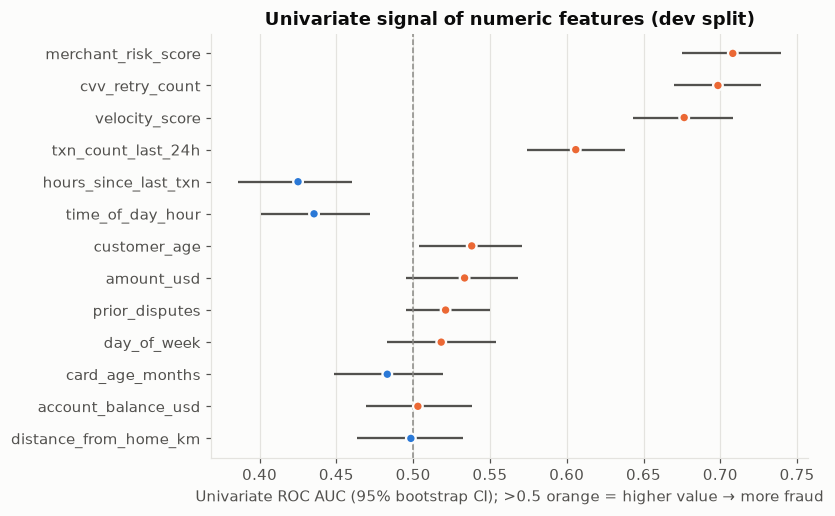

In [5]:
fig, ax = P.plt.subplots(figsize=(7, 5))
P.auc_forest(uni[uni["feature"] != C.ID_COL], ax=ax)
ax.set_title("Univariate signal of numeric features (dev split)")
P.save(fig, "p1_univariate_auc")
P.plt.show()

In [6]:
uni_show = uni.copy()
for c in ["auc", "auc_ci_low", "auc_ci_high"]:
    uni_show[c] = uni_show[c].round(3)
uni_show[["feature", "median_fraud", "median_legit", "auc", "auc_ci_low", "auc_ci_high"]]

,feature,median_fraud,median_legit,auc,auc_ci_low,auc_ci_high
0,merchant_risk_score,48.50,35.40,0.708,0.675,0.740
1,cvv_retry_count,1.00,0.00,0.698,0.670,0.727
2,velocity_score,26.90,18.80,0.676,0.643,0.708
3,txn_count_last_24h,4.00,3.00,0.606,0.574,0.638
4,hours_since_last_txn,4.39,6.19,0.425,0.386,0.460
5,time_of_day_hour,10.00,12.00,0.435,0.401,0.472
6,customer_age,54.00,50.00,0.538,0.504,0.571
7,amount_usd,66.92,57.48,0.533,0.495,0.568
8,prior_disputes,0.00,0.00,0.521,0.495,0.550
9,day_of_week,3.00,3.00,0.518,0.483,0.554


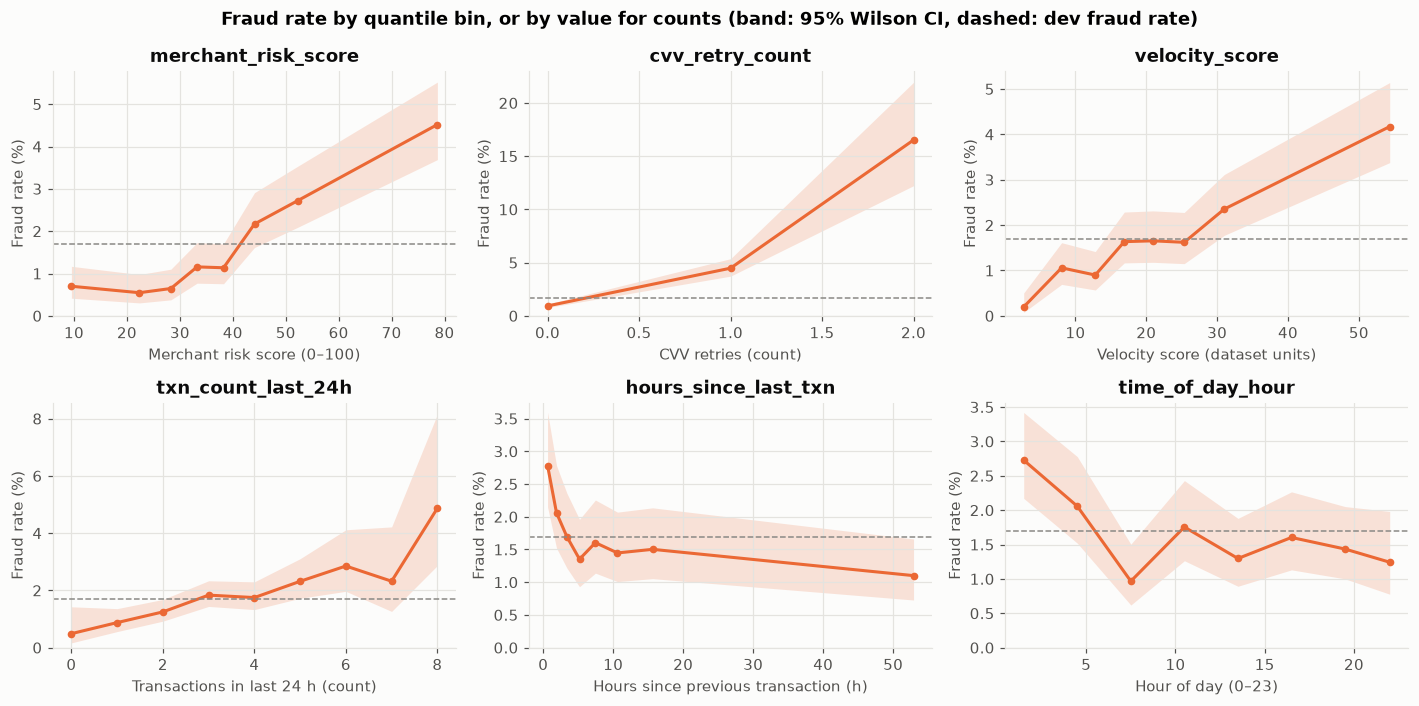

In [7]:
units = {
    "merchant_risk_score": "Merchant risk score (0–100)",
    "cvv_retry_count": "CVV retries (count)",
    "velocity_score": "Velocity score (dataset units)",
    "txn_count_last_24h": "Transactions in last 24 h (count)",
    "hours_since_last_txn": "Hours since previous transaction (h)",
    "time_of_day_hour": "Hour of day (0–23)",
    "amount_usd": "Transaction amount (USD, log scale)",
}
top = [f for f in uni["feature"] if f != C.ID_COL][:6]
fig, axes = P.plt.subplots(2, 3, figsize=(13, 6.5))
for ax, f in zip(axes.ravel(), top):
    binned = S.binned_rate(dev, f, n_bins=8)
    P.binned_rate_line(binned, base_rate, xlabel=units.get(f, f), ax=ax)
    ax.set_title(f)
fig.suptitle(
    "Fraud rate by quantile bin, or by value for counts (band: 95% Wilson CI, "
    "dashed: dev fraud rate)",
    fontweight="bold",
)
fig.tight_layout()
P.save(fig, "p1_binned_rates_top_numeric")
P.plt.show()

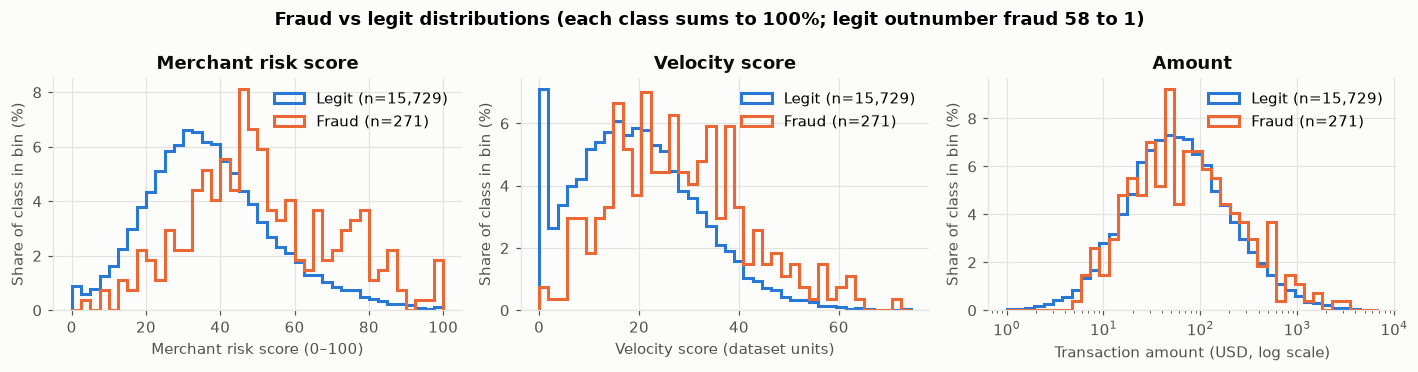

In [8]:
fig, axes = P.plt.subplots(1, 3, figsize=(13, 3.4))
P.class_hist(dev, "merchant_risk_score", units["merchant_risk_score"], ax=axes[0])
P.class_hist(dev, "velocity_score", units["velocity_score"], ax=axes[1])
P.class_hist(dev, "amount_usd", units["amount_usd"], ax=axes[2], logx=True)
for ax, t in zip(axes, ["Merchant risk score", "Velocity score", "Amount"]):
    ax.set_title(t)
fig.suptitle(
    f"Fraud vs legit distributions (each class sums to 100%; legit outnumber fraud "
    f"{(len(dev) - n_fraud) / n_fraud:.0f} to 1)",
    fontweight="bold",
)
fig.tight_layout()
P.save(fig, "p1_class_distributions")
P.plt.show()

## 3. Categorical and boolean features

Association with the target is measured with Cramér's V (0 = none, 1 = perfect) and a chi-square
test. With 11 tests, a Bonferroni threshold of 0.05/11 is used to call a result significant.

In [9]:
disc = C.CATEGORICAL_COLS + C.BOOLEAN_COLS
assoc = pd.DataFrame([S.chi2_association(dev, c) for c in disc])
bonf = 0.05 / len(disc)
assoc["significant_bonferroni"] = assoc["p_value"] < bonf
assoc = assoc.sort_values("cramers_v", ascending=False).reset_index(drop=True)
assoc.assign(
    p_value=assoc["p_value"].map(lambda p: f"{p:.1e}"), cramers_v=assoc["cramers_v"].round(3)
)

,feature,chi2,dof,p_value,cramers_v,n_levels,significant_bonferroni
0,ip_country_mismatch,272.589488,1,3.1e-61,0.131,2,True
1,billing_shipping_mismatch,172.623647,1,2.0e-39,0.104,2,True
2,auth_method,132.711776,4,1.0e-27,0.091,5,True
3,is_foreign_transaction,117.368311,1,2.4e-27,0.086,2,True
4,merchant_category,103.609530,11,3.4e-17,0.080,12,True
5,is_new_merchant,99.468521,1,2.0e-23,0.079,2,True
6,is_ai_generated_scam_attempt,73.766138,1,8.8e-18,0.068,2,True
7,used_vpn,54.908837,1,1.3e-13,0.059,2,True
8,channel,8.922613,4,6.3e-02,0.024,5,False
9,device_type,5.033376,7,6.6e-01,0.018,8,False


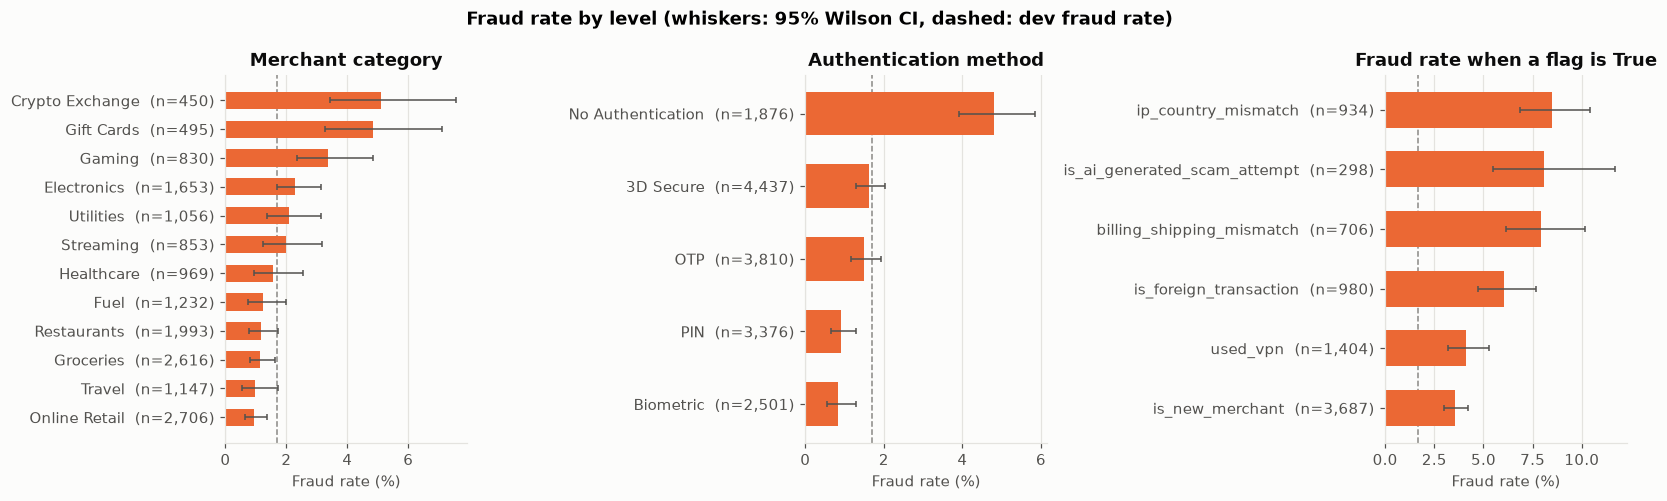

In [10]:
rates = pd.concat([S.rate_table(dev, c) for c in disc], ignore_index=True)
bool_true = rates[rates["feature"].isin(C.BOOLEAN_COLS) & rates["level"].eq("True")].copy()
bool_true["level"] = bool_true["feature"]
fig, axes = P.plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1]})
P.rate_bars(
    rates[rates["feature"] == "merchant_category"], base_rate, ax=axes[0], title="Merchant category"
)
P.rate_bars(
    rates[rates["feature"] == "auth_method"], base_rate, ax=axes[1], title="Authentication method"
)
P.rate_bars(bool_true, base_rate, ax=axes[2], title="Fraud rate when a flag is True")
for ax in axes:
    ax.set_xlabel("Fraud rate (%)")
fig.suptitle(
    "Fraud rate by level (whiskers: 95% Wilson CI, dashed: dev fraud rate)", fontweight="bold"
)
fig.tight_layout()
P.save(fig, "p1_rate_bars")
P.plt.show()

## 4. Money at risk

A missed fraud costs (part of) its amount, so it matters how fraud dollars are spread across cases.

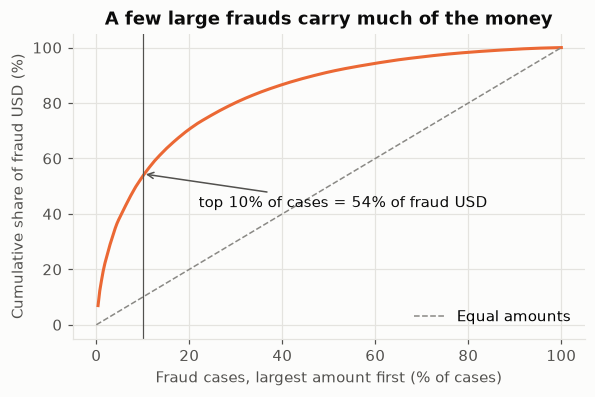

fraud_total_usd                46735.700
fraud_median_usd                  66.920
legit_median_usd                  57.480
fraud_max_usd                   3236.340
top10pct_fraud_cases              28.000
top10pct_share_of_fraud_usd        0.544
fraud_min_usd                      5.140
legit_min_usd                      1.000
legit_share_below_fraud_min        0.019
dtype: float64

In [11]:
fraud_amt = np.sort(dev.loc[dev[C.TARGET] == 1, C.AMOUNT_COL].to_numpy())[::-1]
cum_share = np.cumsum(fraud_amt) / fraud_amt.sum()
top10_n = int(np.ceil(0.10 * len(fraud_amt)))
top10_share = float(cum_share[top10_n - 1])
legit_amt = dev.loc[dev[C.TARGET] == 0, C.AMOUNT_COL]
amount_stats = {
    "fraud_total_usd": float(fraud_amt.sum()),
    "fraud_median_usd": float(np.median(fraud_amt)),
    "legit_median_usd": float(legit_amt.median()),
    "fraud_max_usd": float(fraud_amt.max()),
    "top10pct_fraud_cases": top10_n,
    "top10pct_share_of_fraud_usd": top10_share,
    "fraud_min_usd": float(fraud_amt.min()),
    "legit_min_usd": float(legit_amt.min()),
    "legit_share_below_fraud_min": float((legit_amt < fraud_amt.min()).mean()),
}

fig, ax = P.plt.subplots(figsize=(6, 3.6))
x = np.arange(1, len(fraud_amt) + 1) / len(fraud_amt) * 100
ax.plot(x, cum_share * 100, color=P.FRAUD, lw=2)
ax.plot([0, 100], [0, 100], color=P.NEUTRAL, ls="--", lw=1, label="Equal amounts")
ax.axvline(10, color=P.INK_2, lw=0.8)
ax.annotate(
    f"top 10% of cases = {100 * top10_share:.0f}% of fraud USD",
    xy=(10, 100 * top10_share),
    xytext=(22, 100 * top10_share - 12),
    arrowprops={"arrowstyle": "->", "color": P.INK_2},
    color=P.INK,
)
ax.set_xlabel("Fraud cases, largest amount first (% of cases)")
ax.set_ylabel("Cumulative share of fraud USD (%)")
ax.set_title("A few large frauds carry much of the money")
ax.legend(loc="lower right")
P.save(fig, "p1_fraud_amount_concentration")
P.plt.show()
pd.Series(amount_stats).round(3)

In [12]:
display(
    Markdown(
        f"**A floor on fraud amounts.** The smallest fraud in dev is "
        f"${amount_stats['fraud_min_usd']:.2f}, while "
        f"{100 * amount_stats['legit_share_below_fraud_min']:.1f}% of legit transactions are smaller "
        f'(down to ${amount_stats["legit_min_usd"]:.2f}). A tree model may learn "tiny amount ⇒ legit" for that small slice. '
        f"This looks like a property of how the dataset was produced rather than of fraud in general, "
        f"so it is noted as a dataset-specific signal, not a finding about card fraud."
    )
)

**A floor on fraud amounts.** The smallest fraud in dev is $5.14, while 1.9% of legit transactions are smaller (down to $1.00). A tree model may learn "tiny amount ⇒ legit" for that small slice. This looks like a property of how the dataset was produced rather than of fraud in general, so it is noted as a dataset-specific signal, not a finding about card fraud.

## 5. Do red flags add up?

Count, per transaction, how many of these binary warning signs are present:
foreign transaction, new merchant, VPN, IP-country mismatch, billing/shipping mismatch,
AI-generated scam attempt, no authentication, and at least one CVV retry.

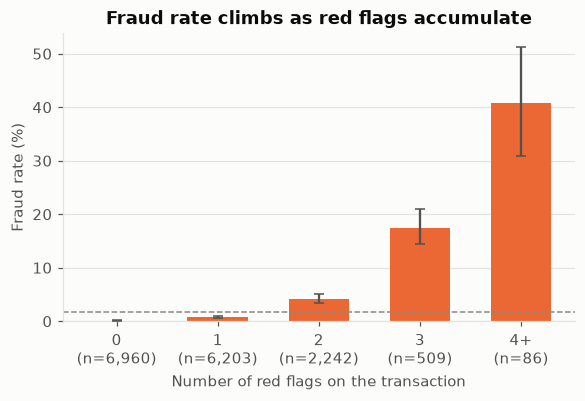

,level,n,n_fraud,fraud_rate,ci_low,ci_high,lift
0,0,6960,7,0.0010,0.0005,0.0021,0.0594
1,1,6203,47,0.0076,0.0057,0.0101,0.4473
2,2,2242,93,0.0415,0.0340,0.0505,2.4491
3,3,509,89,0.1749,0.1443,0.2103,10.3234
4,4+,86,35,0.4070,0.3093,0.5126,24.0281


In [13]:
flags = (
    dev[C.BOOLEAN_COLS].astype(int).sum(axis=1)
    + dev["auth_method"].eq("No Authentication").astype(int)
    + dev["cvv_retry_count"].gt(0).astype(int)
)
dev_flags = dev.assign(n_red_flags=flags.clip(upper=4))
flag_tab = S.rate_table(dev_flags, "n_red_flags").sort_values("level").reset_index(drop=True)
flag_tab["level"] = flag_tab["level"].replace({"4": "4+"})

fig, ax = P.plt.subplots(figsize=(6, 3.4))
xx = np.arange(len(flag_tab))
ax.bar(xx, flag_tab["fraud_rate"] * 100, color=P.FRAUD, width=0.6, zorder=2)
ax.errorbar(
    xx,
    flag_tab["fraud_rate"] * 100,
    yerr=[
        (flag_tab["fraud_rate"] - flag_tab["ci_low"]) * 100,
        (flag_tab["ci_high"] - flag_tab["fraud_rate"]) * 100,
    ],
    fmt="none",
    ecolor=P.INK_2,
    capsize=3,
    zorder=3,
)
ax.axhline(base_rate * 100, color=P.NEUTRAL, ls="--", lw=1)
ax.set_xticks(xx, [f"{lvl}\n(n={n:,})" for lvl, n in zip(flag_tab["level"], flag_tab["n"])])
ax.set_xlabel("Number of red flags on the transaction")
ax.set_ylabel("Fraud rate (%)")
ax.grid(axis="x", visible=False)
ax.set_title("Fraud rate climbs as red flags accumulate")
P.save(fig, "p1_red_flags")
P.plt.show()
flag_tab[["level", "n", "n_fraud", "fraud_rate", "ci_low", "ci_high", "lift"]].round(4)

## 6. Redundancy between numeric features

Strongly correlated inputs would make logistic-regression coefficients unstable.

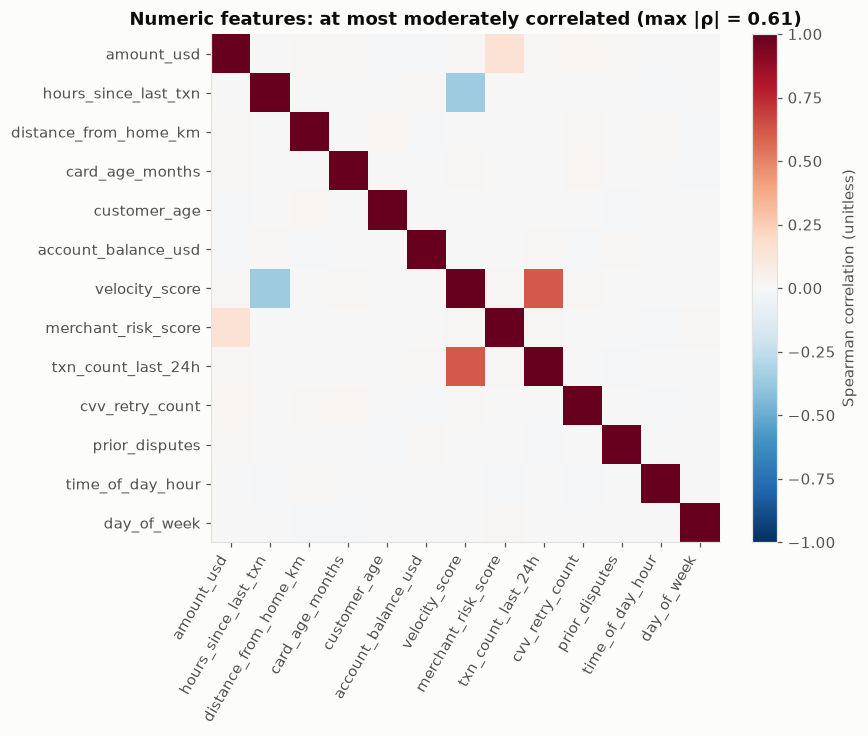

Largest absolute Spearman correlation between two numeric features: **0.610** (`velocity_score` vs `txn_count_last_24h`).

In [14]:
rho = dev[C.NUMERIC_COLS].corr(method="spearman")
off = rho.where(~np.eye(len(rho), dtype=bool)).abs()
pair = off.stack().idxmax()
max_rho = float(off.to_numpy()[~np.isnan(off.to_numpy())].max())

fig, ax = P.plt.subplots(figsize=(7.5, 6))
im = ax.imshow(rho.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=60, ha="right")
ax.set_yticks(range(len(rho)), rho.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman correlation (unitless)")
ax.set_title(f"Numeric features: at most moderately correlated (max |ρ| = {max_rho:.2f})")
P.save(fig, "p1_spearman")
P.plt.show()
display(
    Markdown(
        f"Largest absolute Spearman correlation between two numeric features: "
        f"**{max_rho:.3f}** (`{pair[0]}` vs `{pair[1]}`)."
    )
)

## 7. Save artifacts

In [15]:
write_csv(uni.drop(columns=["iqr_fraud", "iqr_legit"]), "p1_univariate_numeric")
write_csv(rates, "p1_rate_tables")
write_csv(assoc, "p1_categorical_association")
write_csv(flag_tab, "p1_red_flags")
eda_summary = {
    "scope": "dev split only",
    "n_rows": len(dev),
    "n_fraud": n_fraud,
    "fraud_rate": base_rate,
    "leakage_screen": {
        "alarm_threshold_auc": 0.95,
        "max_direction_free_auc": max_auc_any,
        "max_feature": max_sep["feature"],
        "transaction_id_auc": float(id_row["auc"]),
        "transaction_id_auc_ci": [float(id_row["auc_ci_low"]), float(id_row["auc_ci_high"])],
        "alarm_triggered": max_auc_any > 0.95,
    },
    "ai_scam_flag": {
        "decision": "keep; also report model without it",
        **ai_true[["n", "n_fraud", "fraud_rate", "ci_low", "ci_high"]].to_dict(),
    },
    "top_numeric": uni[uni["feature"] != C.ID_COL]
    .head(5)[["feature", "auc", "auc_ci_low", "auc_ci_high"]]
    .to_dict(orient="records"),
    "top_categorical": assoc.head(5)[["feature", "cramers_v", "p_value"]].to_dict(orient="records"),
    "n_discrete_significant_bonferroni": int(assoc["significant_bonferroni"].sum()),
    "n_discrete_tested": len(assoc),
    "not_significant": assoc.loc[~assoc["significant_bonferroni"], "feature"].tolist(),
    "amount_at_risk": amount_stats,
    "red_flags": flag_tab[["level", "n", "n_fraud", "fraud_rate", "ci_low", "ci_high"]].to_dict(
        orient="records"
    ),
    "max_abs_spearman": {"value": max_rho, "pair": list(pair)},
}
p = write_json(eda_summary, "p1_eda_summary")
print(f"wrote {p.relative_to(C.ROOT)} and 4 CSV tables")

wrote reports/p1_eda_summary.json and 4 CSV tables


## Summary

In [16]:
t5 = uni[uni["feature"] != C.ID_COL].head(3)
t5_txt = ", ".join(
    f"`{r.feature}` {r.auc:.2f} ({r.auc_ci_low:.2f}–{r.auc_ci_high:.2f})" for r in t5.itertuples()
)
a3 = ", ".join(f"`{r.feature}` {r.cramers_v:.3f}" for r in assoc.head(3).itertuples())
weak = ", ".join(f"`{f}`" for f in eda_summary["not_significant"])
f0 = flag_tab.iloc[0]
f4 = flag_tab.iloc[-1]
display(
    Markdown(f"""
- **No leakage alarm.** Strongest single feature reaches AUC {max_auc_any:.3f}; row order carries
  no signal. `is_ai_generated_scam_attempt` behaves like a normal risk signal and is kept.
- **Signal is real but spread thin.** Top numeric features by AUC (95% CI): {t5_txt}.
  Strongest categorical/boolean associations (Cramér's V): {a3}. Not significant after
  Bonferroni: {weak}.
- **Red flags add up.** Fraud rate goes from {100 * f0["fraud_rate"]:.2f}% with {f0["level"]} flags to
  {100 * f4["fraud_rate"]:.1f}% (95% CI {100 * f4["ci_low"]:.1f}–{100 * f4["ci_high"]:.1f}%) with
  {f4["level"]}. Each extra flag multiplies the odds, which is the pattern a logistic model
  captures directly; P2 tests whether trees add anything beyond it.
- **Money is concentrated.** The largest 10% of fraud cases ({top10_n}) hold
  {100 * top10_share:.0f}% of fraud dollars (dev total ${amount_stats["fraud_total_usd"]:,.0f}),
  so an amount-aware cost will push the threshold to favour catching large frauds. No fraud is
  below ${amount_stats["fraud_min_usd"]:.2f} while {100 * amount_stats["legit_share_below_fraud_min"]:.1f}%
  of legit transactions are — a small, dataset-specific pattern a tree model may exploit.
- **No redundant inputs.** The most correlated pair is `{pair[0]}` / `{pair[1]}`
  (|Spearman| {max_rho:.2f}, moderate), so all 24 features go into P2 unchanged (logistic
  regression is regularised); `transaction_id` is excluded.
- **Expectation for P2:** no single feature separates the classes well, so PR-AUC will be far from 1.
  The no-skill PR-AUC is {base_rate:.4f}.
""")
)


- **No leakage alarm.** Strongest single feature reaches AUC 0.708; row order carries
  no signal. `is_ai_generated_scam_attempt` behaves like a normal risk signal and is kept.
- **Signal is real but spread thin.** Top numeric features by AUC (95% CI): `merchant_risk_score` 0.71 (0.68–0.74), `cvv_retry_count` 0.70 (0.67–0.73), `velocity_score` 0.68 (0.64–0.71).
  Strongest categorical/boolean associations (Cramér's V): `ip_country_mismatch` 0.131, `billing_shipping_mismatch` 0.104, `auth_method` 0.091. Not significant after
  Bonferroni: `channel`, `device_type`, `card_type`.
- **Red flags add up.** Fraud rate goes from 0.10% with 0 flags to
  40.7% (95% CI 30.9–51.3%) with
  4+. Each extra flag multiplies the odds, which is the pattern a logistic model
  captures directly; P2 tests whether trees add anything beyond it.
- **Money is concentrated.** The largest 10% of fraud cases (28) hold
  54% of fraud dollars (dev total $46,736),
  so an amount-aware cost will push the threshold to favour catching large frauds. No fraud is
  below $5.14 while 1.9%
  of legit transactions are — a small, dataset-specific pattern a tree model may exploit.
- **No redundant inputs.** The most correlated pair is `velocity_score` / `txn_count_last_24h`
  (|Spearman| 0.61, moderate), so all 24 features go into P2 unchanged (logistic
  regression is regularised); `transaction_id` is excluded.
- **Expectation for P2:** no single feature separates the classes well, so PR-AUC will be far from 1.
  The no-skill PR-AUC is 0.0169.
